# Project 2 — Consumer Search on Expedia

Run from top to bottom. The notebook contains Sections 1.1, 2.1–2.5 and 3. It reads train.parquet from the working folder when available and otherwise from Downloads.

In Part 3, the baseline fits bookings and the extension uses clicks to separate utility from search costs. Both models use the same booking estimates.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scienceplots
from scipy.optimize import root, minimize
from scipy.special import digamma

dark_blue = "#16446F"
light_blue = "#5698C6"
blues = [dark_blue, light_blue]

plt.style.use(["science", "no-latex"])
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Palatino Linotype", "DejaVu Serif"],
    "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=blues),
    "lines.linewidth": 1.45,
    "lines.markersize": 3.5,
    "legend.fontsize": 9,
})

## 1.1: Load the data

A session is a single search, identified by `srch_id`. A listing is one hotel in the results of that search, whether or not the user saw it or clicked it. `random_bool` identifies the ranking group. It is 0 for Expedia's usual order and 1 for a randomized order. Every recorded session has at least one click. The Expedia group includes a disproportionate share of sessions that ended in a booking.

In [2]:
data_path = Path("train.parquet")
if not data_path.exists():
    data_path = Path.home() / "Downloads" / "train.parquet"

columns = ["srch_id", "position", "random_bool", "price_usd", "click_bool", "booking_bool",
           "prop_starrating", "prop_review_score", "prop_location_score1",
           "promotion_flag", "srch_destination_id"]
data = pd.read_parquet(data_path, columns=columns)
data = data.astype({
    "srch_id": "int32", "srch_destination_id": "int32",
    "position": "int8", "random_bool": "int8", "click_bool": "int8",
    "booking_bool": "int8", "prop_starrating": "int8",
    "promotion_flag": "int8"
})

ranking_names = {0: "Expedia ranking", 1: "Random ranking"}
output = Path("output/simple")
output.mkdir(parents=True, exist_ok=True)

data.head()

,srch_id,position,random_bool,price_usd,click_bool,booking_bool,prop_starrating,prop_review_score,prop_location_score1,promotion_flag,srch_destination_id
0,1,27,1,104.77,0,0,3,3.5,2.83,0,23246
1,1,26,1,170.74,0,0,4,4.0,2.20,0,23246
2,1,21,1,179.80,0,0,3,4.5,2.20,0,23246
3,1,34,1,602.77,0,0,2,4.0,2.83,0,23246
4,1,4,1,143.58,0,0,4,3.5,2.64,0,23246


In [3]:
print("Listings:", len(data))
print("Sessions:", data["srch_id"].nunique())

session_bookings = data.groupby(["random_bool", "srch_id"])["booking_bool"].max()
sample_summary = session_bookings.groupby("random_bool").agg(["size", "mean"])
sample_summary.columns = ["Sessions", "Booking rate"]
sample_summary.rename(index=ranking_names)

Listings: 9917530
Sessions: 399344


,Sessions,Booking rate
random_bool,,
Expedia ranking,277798,0.938624
Random ranking,121546,0.130362


## 1.1(a): Price and displayed position

Use positive prices and take logs because some prices are extremely large. A geometric mean is the exponential of the mean log price.

We also subtract each session's mean log price. This removes price differences between sessions, such as destination or travel dates. The price index equals 100 at the session's geometric mean price.

In [4]:
prices = data.loc[data["price_usd"] > 0,
                  ["srch_id", "position", "random_bool", "price_usd"]].copy()
prices["log_price"] = np.log(prices["price_usd"])

session_means = prices.groupby("srch_id")[["position", "log_price"]].transform("mean")
prices["position_within"] = prices["position"] - session_means["position"]
prices["log_price_within"] = prices["log_price"] - session_means["log_price"]

mean_log_price = prices.groupby(["position", "random_bool"])["log_price"].mean().unstack()
mean_within_log_price = prices.groupby(["position", "random_bool"])["log_price_within"].mean().unstack()

geometric_price = np.exp(mean_log_price).rename(columns=ranking_names)
within_price_index = (100 * np.exp(mean_within_log_price)).rename(columns=ranking_names)

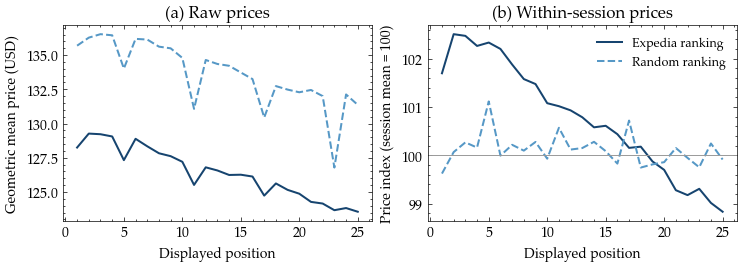

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.65), layout="constrained")

geometric_price.loc[:25].plot(style=["-", "--"], legend=False, ax=axes[0])
axes[0].set_title("(a) Raw prices")
axes[0].set_ylabel("Geometric mean price (USD)")

within_price_index.loc[:25].plot(style=["-", "--"], legend=False, ax=axes[1])
axes[1].set_title("(b) Within-session prices")
axes[1].set_ylabel("Price index (session mean = 100)")
axes[1].axhline(100, color="0.60", linewidth=0.7)
axes[1].legend(frameon=False)

for ax in axes:
    ax.set_xlabel("Displayed position")
fig.savefig(output / "price_profiles.pdf")
plt.show()

The within-session slope is the regression coefficient after subtracting session means:

$$\hat\beta=\frac{\sum (j-\bar j_i)(\log p_{ij}-\overline{\log p}_i)}{\sum(j-\bar j_i)^2}.$$

Convert it to a percentage price difference per position using $100(e^{\hat\beta}-1)$.

In [6]:
price_slopes = []

for ranking in [0, 1]:
    group = prices[prices["random_bool"] == ranking]
    x = group["position_within"]
    y = group["log_price_within"]
    slope = (x * y).sum() / (x ** 2).sum()
    price_slopes.append([ranking_names[ranking], slope, 100 * (np.exp(slope) - 1)])

price_slopes = pd.DataFrame(price_slopes,
                           columns=["Ranking", "Log-price slope", "Percent per position"])
price_slopes.round(6)

,Ranking,Log-price slope,Percent per position
0,Expedia ranking,-0.002000,-0.199790
1,Random ranking,-0.000093,-0.009328


**Interpretation:** within the same session, price is almost flat under random ranking and falls modestly down the Expedia ranking. Raw random-ranking prices can slope because different positions contain different mixes of sessions.

## 1.1(b): Booking conditional on a click

Keep clicked listings and calculate the mean of `booking_bool`. This gives bookings divided by clicks.

Use five-position bands up to position 25 because some individual positions have very few clicks. Zero-price listings remain in this calculation.

Positions 5, 11, 17 and 23 were reserved for opaque offers, which hide the hotel's name until booking. This explains the gaps in ordinary hotel listings (Ursu, 2018).

In [7]:
clicked = data[(data["click_bool"] == 1) & (data["position"] <= 25)].copy()
clicked["Position band"] = pd.cut(clicked["position"],
                                  bins=[0, 5, 10, 15, 20, 25],
                                  labels=["1-5", "6-10", "11-15", "16-20", "21-25"])

conversion = clicked.groupby(["Position band", "random_bool"], observed=True)["booking_bool"].mean().unstack()
conversion = conversion.rename(columns=ranking_names)

(100 * conversion).round(2)

random_bool,Expedia ranking,Random ranking
Position band,,
1-5,88.49,13.21
6-10,83.87,11.82
11-15,80.95,11.23
16-20,79.58,9.77
21-25,77.57,9.21


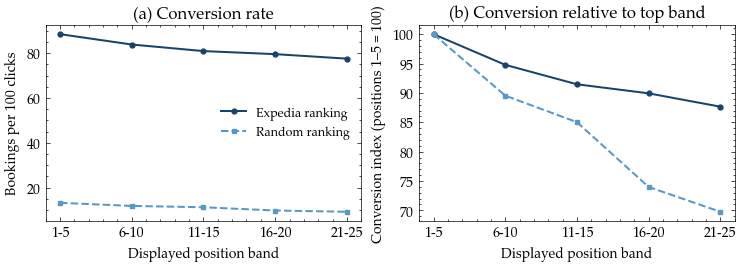

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.65), layout="constrained")

(100 * conversion).plot(style=["o-", "s--"], legend=False, ax=axes[0])
axes[0].set_title("(a) Conversion rate")
axes[0].set_ylabel("Bookings per 100 clicks")
axes[0].legend(frameon=False, loc="center right")

conversion_index = 100 * conversion / conversion.iloc[0]
conversion_index.plot(style=["o-", "s--"], legend=False, ax=axes[1])
axes[1].set_title("(b) Conversion relative to top band")
axes[1].set_ylabel("Conversion index (positions 1–5 = 100)")

for ax in axes:
    ax.set_xlabel("Displayed position band")
fig.savefig(output / "conversion_bands.pdf")
plt.show()

In [9]:
conversion_changes = pd.DataFrame({
    "Decline in percentage points": 100 * (conversion.iloc[0] - conversion.iloc[-1]),
    "Relative decline (%)": 100 * (1 - conversion.iloc[-1] / conversion.iloc[0])
})
conversion_changes.round(2)

,Decline in percentage points,Relative decline (%)
random_bool,,
Expedia ranking,10.92,12.34
Random ranking,3.99,30.24


**Interpretation:** conversion falls in both samples. It falls from 88.49% to 77.57% under Expedia and from 13.21% to 9.21% under random ranking.

Bookings are oversampled under the Expedia ranking, so the levels cannot tell us which ranking works better. Conditioning on clicks also selects consumers and hotels, even under randomized positions. Normalizing the curves compares shapes but does not remove selection. Displayed position is not the observed chronological order of clicks.

## 2.1: Prices and search order

**Arbatskaya:** active firms sell a homogeneous good and prices fall in the exogenous search order, $p_1>p_2>\cdots$. High-search-cost consumers stop early; further search must promise lower prices. This matches the sign of Expedia's descriptive price gradient.

**Zhou:** products have uncertain, consumer-specific matches. In the uniform ordered-search equilibrium, prices rise with search order, $p_1<p_2<\cdots$. Early firms compete with unexplored alternatives; later visitors have rejected previous offers and have fewer remaining alternatives. This has the opposite sign to the Expedia price gradient. Random displayed order is not either model's endogenous search order.

## 2.2: Purchase after visiting a firm

In Arbatskaya, purchase depends on the observed price, expected later savings and the search costs of the consumers who reach that firm. In Zhou it also depends on how well the product suits the consumer (the match value), the best earlier offer and the option to buy nothing. Free recall means the consumer can return to an earlier offer without paying again. The Expedia conversion profiles alone cannot distinguish the two mechanisms.

## 2.3: Why do the conversion profiles differ?

Expedia's decline is larger in percentage points but smaller relative to its initial conversion rate. Quality sorting and personalization may matter, alongside visible prices, click selection and different sampling. The observed profiles alone do not isolate a causal matching benefit of Expedia's algorithm.

## 2.4(i): Optimal search

Actual prices are $x=\tilde p_1$ and $y=\tilde p_2$; expected prices are $p_1,p_2$. Match values are independent uniforms on $[0,1]$, costs of production are zero, recall is free and the outside payoff is zero.

Visit Firm 1 for free. Define

$$a=1-\sqrt{2s},\qquad z=a-p_2,$$

because $s=\int_a^1(u-a)du=(1-a)^2/2$.

After observing Firm 1, the best payoff is $v=\max\{0,u_1-x\}$. Search Firm 2 iff $v<z$; otherwise stop. If $z\leq0$, do not search Firm 2. After both visits choose the largest of $u_1-x$, $u_2-y$ and zero.

## 2.4(ii): Demand and profit

For the interior region around equilibrium, $z>0$, $x+z<1$, $y+z<1$:

- Firm 1 sells immediately to mass $1-x-z$.
- Consumers with $u_1=x+v$, $0\leq v<z$, search further and return to Firm 1 if $u_2<y+v$.
- Firm 2 sells to consumers whose first offer is negative, and to those with a positive first offer below $z$ who find a better second offer.

Therefore

$$D_1=1-x-z+\int_0^z(y+v)dv=1-x-z+yz+\frac{z^2}{2},$$
$$D_2=x(1-y)+\int_0^z(1-y-v)dv=(x+z)(1-y)-\frac{z^2}{2},$$
$$\pi_1=xD_1,\qquad\pi_2=yD_2.$$

Consumer mass is normalized to one. If $z\leq0$, $D_1=1-F(x)$ and $D_2=0$. Outside the interior region the uniform CDF must be bounded between zero and one.

## 2.4(iii): First-order conditions

Differentiate each profit in its actual price, **holding expected prices and hence $z$ fixed**. Only afterwards impose $x=p_1$, $y=p_2$, $z=a-p_2$:

$$1-2p_1-z+p_2z+\frac{z^2}{2}=0,$$
$$(p_1+z)(1-2p_2)-\frac{z^2}{2}=0.$$

The following function contains exactly these two equations.

In [10]:
def foc(prices, a):
    p1, p2 = prices
    z = a - p2
    return [1 - 2*p1 - z + p2*z + z**2/2,
            (p1 + z)*(1 - 2*p2) - z**2/2]

## 2.4(iv): Solve for different search costs

For each value of `s`, solve the two equations for `p1` and `p2`, then calculate demands and profits.

In [11]:
search_costs = [0.001, 0.01, 0.025, 0.05, 0.075, 0.10, 0.12]
results = []

for s in search_costs:
    a = 1 - np.sqrt(2*s)
    p1, p2 = root(foc, [0.45, 0.47], args=(a,)).x
    z = a - p2

    D1 = 1 - p1 - z + p2*z + z**2/2
    D2 = (p1 + z)*(1 - p2) - z**2/2

    results.append({"s": s, "a": a, "p1": p1, "p2": p2,
                    "Profit 1": p1*D1, "Profit 2": p2*D2})

equilibrium = pd.DataFrame(results)
equilibrium[["s", "p1", "p2"]].round(5)

,s,p1,p2
0,0.001,0.41816,0.42610
1,0.010,0.42944,0.45024
2,0.025,0.44184,0.46837
3,0.050,0.45869,0.48497
4,0.075,0.47351,0.49406
5,0.100,0.48716,0.49865
6,0.120,0.49749,0.49995


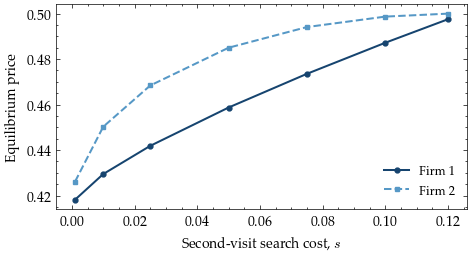

In [12]:
fig, ax = plt.subplots(figsize=(4.7, 2.55), layout="constrained")
ax.plot(equilibrium["s"], equilibrium["p1"], "o-", label="Firm 1")
ax.plot(equilibrium["s"], equilibrium["p2"], "s--", label="Firm 2")
ax.set_xlabel("Second-visit search cost, $s$")
ax.set_ylabel("Equilibrium price")
ax.legend(frameon=False, loc="lower right")
fig.savefig(output / "equilibrium_prices.pdf")
plt.show()

Firm 1 charges less at the reported search costs. At $s=0.05$, $p_1=0.45869$ and $p_2=0.48497$. Both prices increase with search costs. They approach $\sqrt{2}-1$ as $s\downarrow0$ and $1/2$ as $s\uparrow1/8$.

## 2.5(i): Can Firm 2 gain by moving first?

The platform adds an incentive to undercut and receive the free first visit. Firm 2 must prefer its old profit to any deviation $q\leq p_1$:

$$\pi_2^{\mathrm{old}}\geq\sup_{0\leq q\leq p_1}qD_1(q,p_1;a-p_1).$$

Under the stated tie rule, setting $q=p_1$ moves Firm 2 first. The unchanged rival still charges $p_1$, so the second-visit threshold becomes $a-p_1$. Firm 2's new profit is

$$\pi_2^{\mathrm{switch}}=p_1\left[1-a+\frac{a^2-p_1^2}{2}\right].$$

There is also a constraint against Firm 1 raising its price enough to lose first place. One profitable deviation is enough to reject the old equilibrium.

In [13]:
equilibrium["Profit 2 after moving first"] = equilibrium["p1"] * (
    1 - equilibrium["a"] + (equilibrium["a"]**2 - equilibrium["p1"]**2)/2
)
equilibrium["Gain"] = equilibrium["Profit 2 after moving first"] - equilibrium["Profit 2"]

equilibrium[["s", "p1", "p2", "Profit 2", "Profit 2 after moving first", "Gain"]].round(5)

,s,p1,p2,Profit 2,Profit 2 after moving first,Gain
0,0.001,0.41816,0.42610,0.17200,0.17294,0.00094
1,0.010,0.42944,0.45024,0.16983,0.17942,0.00958
2,0.025,0.44184,0.46837,0.16450,0.18884,0.02434
3,0.050,0.45869,0.48497,0.15464,0.20403,0.04939
4,0.075,0.47351,0.49406,0.14454,0.21918,0.07464
5,0.100,0.48716,0.49865,0.13459,0.23449,0.09990
6,0.120,0.49749,0.49995,0.12688,0.24688,0.12000


The gain is positive at every reported search cost. At $s=0.05$, Firm 2's profit rises from $0.15464$ to $0.20403$. Thus the fixed-order prices are not an equilibrium once the platform responds to actual prices.

## 2.5(ii): What might the new equilibrium look like?

Firms now compete for the free first visit. Stronger price competition and mixed pricing strategies are plausible. Product differentiation means prices need not fall to marginal cost. Consumers would be expected to benefit from the stronger competition, but a complete welfare result requires solving the new equilibrium, including consumer beliefs and search behavior.

## Sources and AI use

Lectures 6–7 and Armstrong (2017). [Ordered Consumer Search](https://doi.org/10.1093/jeea/jvx017).

ChatGPT (OpenAI, 23 November 2026) assisted with the derivations, code and prose. Review and acknowledge the material used in your submitted report.

# 3. Empirical part

## 3.1 Demand and search

Estimate on all recorded sessions in both groups. Keep each session's full choice set, meaning all hotels in its search results. For estimation, set displayed prices outside USD 10–1,000 to the nearest endpoint, using the range in Ursu (2018). The ranking exercise uses 1,000 randomly sampled Expedia lists across all destinations.

In [14]:
# Release the temporary arrays from the full-sample price plots.
del prices, session_means

# Sort the rows by session if needed so each list is contiguous.
if not data["srch_id"].is_monotonic_increasing:
    data = data.sort_values("srch_id")

expedia_ids = data.loc[data["random_bool"].eq(0), "srch_id"].drop_duplicates()
cf_ids = expedia_ids.sample(n=1000, random_state=7)

data["price100"] = data["price_usd"].clip(10, 1000) / 100
data = data.rename(columns={
    "prop_starrating": "stars", "prop_review_score": "reviews",
    "prop_location_score1": "location",
    "promotion_flag": "promotion"
})
for rating in ["stars", "reviews"]:
    has_rating = data[rating].gt(0)
    median = data.loc[has_rating, rating].median()
    data[f"no_{rating}"] = (~has_rating).astype("int8")
    data[rating] = data[rating].where(has_rating, median)

data["expedia_arm"] = 1 - data["random_bool"]
data["expedia_position"] = data["expedia_arm"] * data["position"]

cf = data[data["srch_id"].isin(cf_ids)].sort_values(["srch_id", "position"])

samples = data.groupby("random_bool").agg(
    Sessions=("srch_id", "nunique"), Listings=("srch_id", "size"),
    Destinations=("srch_destination_id", "nunique")
).rename(index=ranking_names)
samples

,Sessions,Listings,Destinations
random_bool,,,
Expedia ranking,277798,6977878,20280
Random ranking,121546,2939652,14509


### Baseline — fit bookings

For session $i$ and hotel $j$, utility is $u_{ij}=\delta_{ij}+\varepsilon_{ij}$. The consumer knows $\delta_{ij}$ before searching and learns the match value $\varepsilon_{ij}$ by clicking. A higher $\mu_{ij}$ makes search more costly. The outside option $j=0$ means leaving without booking on Expedia and has $\delta_{i0}=\mu_{i0}=0$. In the lecture notes' search model, the probabilities depend on the net booking index $v_{ij}=\delta_{ij}-\mu_{ij}$.
$$s_{ij}=\frac{e^{v_{ij}}}{1+\sum_{k\geq1}e^{v_{ik}}},\qquad
s_{i0}=\frac{1}{1+\sum_{k\geq1}e^{v_{ik}}}.$$
The baseline maximizes $\sum_i\log s_{i,d_i}$, where $d_i$ is the observed choice. Bookings identify the net index, so we set $\mu_{ij}=0$ in the baseline.

Following Ursu (2018), use price in USD 100, stars, guest reviews, Expedia's first location score and whether a promotion was shown. For each rating type, flag zero or missing scores and fill them with the median among positive scores. Both groups share hotel coefficients. Expedia gets its own intercept (baseline hotel appeal relative to leaving) and position slope (the effect of moving one slot down). The ranking exercise uses the randomized intercept and slope because Expedia sorts hotels and its bookings are oversampled.

In [15]:
variables = ["price100", "stars", "no_stars", "reviews", "no_reviews",
             "location", "promotion",
             "position", "expedia_position", "expedia_arm"]
position_col = variables.index("position")
X = data[variables].to_numpy(dtype=float)
group = pd.factorize(data["srch_id"])[0].astype("int32")
first = np.r_[0, np.flatnonzero(np.diff(group)) + 1]
N = len(first)
booking = data["booking_bool"].to_numpy()
click = data["click_bool"].to_numpy()
is_expedia = data["expedia_arm"].to_numpy().astype(bool)
position = data["position"].to_numpy()

def purchase_loss(theta):
    v = np.einsum('ij,j->i', X, theta[:-1]) + theta[-1]
    shift = np.maximum(0, np.maximum.reduceat(v, first))
    e = np.exp(v - shift[group])
    total = np.exp(-shift) + np.add.reduceat(e, first)
    p = e / total[group]
    loss = ((shift + np.log(total)).sum() - v[booking == 1].sum()) / N
    error = p - booking
    gradient = np.r_[np.einsum('ij,i->j', X, error), error.sum()] / N
    return loss, gradient

booking_fit = minimize(purchase_loss, np.r_[np.zeros(len(variables)), -5],
                       jac=True, method="BFGS")
theta = booking_fit.x

e = np.exp(np.einsum('ij,j->i', X, theta[:-1]) + theta[-1])
total = 1 + np.add.reduceat(e, first)
share = e / total[group]
del X, e

### Search extension — match observed click curves

Let $g$ identify the ranking group (randomized or Expedia) and $\ell_{ij}$ the displayed position, with 1 at the top. Set $\mu_{ij}=\gamma_{0g}+\gamma_{1g}\ell_{ij}$, where the intercept and per-slot increase are nonnegative. For each candidate pair, keep the fitted $v_{ij}$ fixed and set $\delta_{ij}=v_{ij}+\mu_{ij}$. The booking fit stays the same. Price and hotel attributes enter utility, while position can affect utility and search costs.

The reservation value $r_{ij}$ is the fallback utility at which the expected gain from clicking equals its cost. The Weitzman index is $w_{ij}=\min\{r_{ij},u_{ij}\}$, with $w_{i0}=u_{i0}$. The consumer clicks $j$ if $r_{ij}\geq W_{i,-j}$, where $W_{i,-j}=\max_{k\ne j}w_{ik}$ includes the outside option. The lecture notes give the click probability as
$$q_{ij}=\mathbb E_{\varepsilon\sim F_0}\left[\frac{1-F_0(\varepsilon+b_{i,-j}-\delta_{ij}+\mu_{ij})}{1-F_0(\varepsilon+b_{i,-j}-\delta_{ij})}\right],\qquad b_{i,-j}=\log\left(1+\sum_{k\ne 0,j}e^{v_{ik}}\right).$$
Here $F_0(z)=\exp(-e^{-z})$ is the standard Gumbel distribution function and $b_{i,-j}$ summarizes the appeal of the other options. At fixed $v_{ij}$, higher $\mu_{ij}$ reduces clicks. The code evaluates that same expectation in closed form. Write the booking odds as $o_{ij}=s_{ij}/(1-s_{ij})$ and define $A_{ij}=o_{ij}e^{\mu_{ij}}$ to obtain
$$q_{ij}=\frac{\psi((1+o_{ij})/A_{ij})-\psi(1/A_{ij})}{A_{ij}},$$
where $\psi$ is the digamma function.

For each group and position $\ell$, compute observed clicks per listing $\bar a_{g\ell}$ and fitted clicks per listing $\bar q_{g\ell}$. Choose the candidate pair that minimizes $\sum_\ell n_{g\ell}(\bar a_{g\ell}-\bar q_{g\ell})^2$, where $n_{g\ell}$ counts those listings. Positions with more listings get more weight. Missing zero-click sessions can affect estimated costs.

In [16]:
def search_probability(share, mu):
    odds = share / (1 - share)
    A = odds * np.exp(mu)
    probability = (digamma((1 + odds) / A) - digamma(1 / A)) / A
    return np.where(mu == 0, 1, probability)

def click_curve_inputs(mask):
    ranks = position[mask]
    counts = np.bincount(ranks)
    observed_clicks = np.bincount(ranks, weights=click[mask])
    return share[mask], ranks, counts, observed_clicks

def click_loss(gamma, shares, ranks, counts, observed_clicks):
    mu = gamma[0] + gamma[1] * ranks
    predicted_clicks = np.bincount(ranks, weights=search_probability(shares, mu))
    used = counts > 0
    gap = (observed_clicks[used] - predicted_clicks[used]) / counts[used]
    return np.average(gap**2, weights=counts[used])

click_fits = []
for mask in [~is_expedia, is_expedia]:
    fit_arm = minimize(click_loss, [3, 0.05], args=click_curve_inputs(mask),
                       bounds=[(0, None), (0, None)], method="L-BFGS-B",
                       options={"ftol": 1e-11, "gtol": 1e-7})
    click_fits.append(fit_arm)
gamma_random, gamma_expedia = [fit.x for fit in click_fits]

search_coefs = np.zeros(len(theta))
search_coefs[position_col] = gamma_random[1]
search_coefs[variables.index("expedia_position")] = gamma_expedia[1] - gamma_random[1]
search_coefs[variables.index("expedia_arm")] = gamma_expedia[0] - gamma_random[0]
search_coefs[-1] = gamma_random[0]

parameters = pd.DataFrame({
    "Net booking index": theta,
    "Utility": theta + search_coefs,
    "Search cost": search_coefs
}, index=variables + ["Inside constant"])
# A dash marks a variable that only enters utility.
parameter_display = parameters.round(3).astype(object)
parameter_display.loc[variables[:position_col], "Search cost"] = "—"
parameter_display.columns = pd.MultiIndex.from_tuples([
    ("Baseline", "Net index"),
    ("Search extension", "Recovered utility"),
    ("Search extension", "Isolated search cost")
])
parameter_display

Baseline  Search extension                     
                 Net index Recovered utility Isolated search cost
price100            -0.782            -0.782                    —
stars                0.299             0.299                    —
no_stars            -0.378            -0.378                    —
reviews              0.249             0.249                    —
no_reviews           -0.54             -0.54                    —
location              0.06              0.06                    —
promotion             0.09              0.09                    —
position            -0.078            -0.001                0.077
expedia_position    -0.027             0.655                0.682
expedia_arm          4.942             4.017               -0.925
Inside constant     -5.085            -2.917                2.168

In [17]:
fit_rows = []
curves = []
for name, mask, cost in [("Random ranking", ~is_expedia, gamma_random),
                         ("Expedia ranking", is_expedia, gamma_expedia)]:
    shares, ranks, counts, observed_clicks = click_curve_inputs(mask)
    predicted = search_probability(shares, cost[0] + cost[1]*ranks)
    predicted_clicks = np.bincount(ranks, weights=predicted)
    used = counts > 0
    curves.append(pd.DataFrame({
        "Arm": name, "Position": np.flatnonzero(used), "Listings": counts[used],
        "Observed": observed_clicks[used] / counts[used],
        "Fitted": predicted_clicks[used] / counts[used]
    }))
    sessions = mask[first].sum()
    fit_rows.append({
        "Arm": name,
        "Observed bookings (%)": 100 * booking[mask].sum()/sessions,
        "Predicted bookings (%)": 100 * (1 - 1/total[mask[first]]).mean(),
        "Observed clicks per session": click[mask].sum()/sessions,
        "Baseline clicks per session": mask.sum()/sessions,
        "Extension clicks per session": predicted.sum()/sessions
    })
fit = pd.DataFrame(fit_rows).set_index("Arm")
click_curves = pd.concat(curves, ignore_index=True)
fit.round(3)

,Observed bookings (%),Predicted bookings (%),Observed clicks per session,Baseline clicks per session,Extension clicks per session
Arm,,,,,
Random ranking,13.036,13.036,1.127,24.186,1.085
Expedia ranking,93.862,93.862,1.104,25.119,1.061


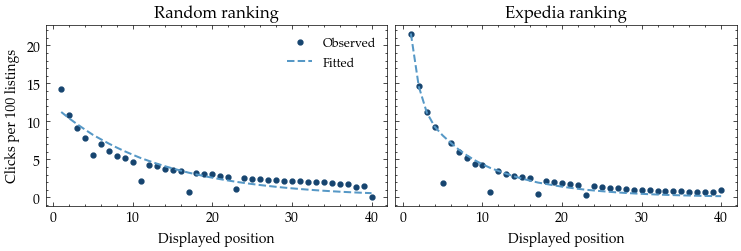

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.5), layout="constrained", sharey=True)

for ax, name in zip(axes, ["Random ranking", "Expedia ranking"]):
    curve = click_curves[click_curves["Arm"].eq(name)]
    ax.plot(curve["Position"], 100*curve["Observed"], "o", label="Observed", color=dark_blue)
    ax.plot(curve["Position"], 100*curve["Fitted"], "--", label="Fitted", color=light_blue)
    ax.set_title(name)
    ax.set_xlabel("Displayed position")

axes[0].set_ylabel("Clicks per 100 listings")
axes[0].legend(frameon=False)
fig.savefig(output / "click_curve_fit.pdf")
plt.show()

### Price equivalent and markup

An improvement of one position raises a hotel's net index by $-\theta_{\rm pos}$. A price increase of $100\theta_{\rm pos}/\theta_{\rm price}$ dollars offsets this change. With one hotel per firm, the pricing first-order condition implies a markup (price minus marginal cost) of $100/[-\theta_{\rm price}(1-s_{ij})]$. Both models share the booking coefficients. Use the randomized position slope. Report the median markup on randomized listings with original prices strictly inside the clipping range, where the price slope applies. Unobserved quality may raise both price and demand, weakening the estimated price sensitivity and inflating the implied markup.

In [19]:
interior = ~is_expedia & data["price_usd"].between(10, 1000, inclusive="neither").to_numpy()
markup = 100 / (-theta[0] * (1 - share[interior]))
economics = pd.Series({
    "Price increase for one position up (USD)": 100 * theta[position_col] / theta[0],
    "Median implied markup (USD)": np.median(markup),
    "Median markup / price (%)": 100 * np.median(markup / data.loc[interior, "price_usd"].to_numpy())
})
economics.round(2)

Price increase for one position up (USD)     10.03
Median implied markup (USD)                 128.33
Median markup / price (%)                   100.88
dtype: float64

## 3.2 Compare three rankings

Keep each Expedia list and its prices fixed. Compare the original positions, a random shuffle and a utility-based order. The utility rule sorts hotels by their estimated attributes, excluding position. Reuse the existing position slots, including the gaps.

Use the intercept, position slope and search costs from the randomized group for all three rankings. Both models predict the same bookings at every ranking because they share the net booking index. The free-search baseline predicts one click per hotel. The extension predicts clicks using the fitted search costs. We add the hotel probabilities to obtain expected clicks per session.

In [20]:
Xcf = cf[variables].to_numpy(float)
Xcf[:, -2:] = 0  # Use the randomized arm for prediction.
group_cf = pd.factorize(cf["srch_id"])[0]
first_cf = np.r_[0, np.flatnonzero(np.diff(group_cf)) + 1]
end_cf = np.r_[first_cf[1:], len(cf)]
old_rank = Xcf[:, position_col].copy()
random_rank = old_rank.copy()
best_rank = old_rank.copy()

v_original = Xcf @ theta[:-1] + theta[-1]
score = v_original - theta[position_col] * old_rank
rng = np.random.default_rng(2026)
for start, end in zip(first_cf, end_cf):
    slots = old_rank[start:end]
    random_rank[start:end] = rng.permutation(slots)
    order = np.argsort(-score[start:end], kind="stable")
    best_rank[start + order] = slots

rankings = {"Expedia": old_rank, "Random": random_rank, "Utility-based": best_rank}

### Robustness — let search costs be the same at every rank

Set $\gamma_{\rm pos}=0$ and re-estimate the randomized arm search constant with the same click criterion. The position effect then enters only through utility. Booking predictions stay the same by construction. Click predictions can change, showing what the estimated position effect on search contributes.

In [21]:
random = ~is_expedia
gamma_constant = minimize(click_loss, [gamma_random[0], 0],
                          args=click_curve_inputs(random),
                          bounds=[(0, None), (0, 0)], method="L-BFGS-B",
                          options={"ftol": 1e-11, "gtol": 1e-7}).x

rows = []
for name, ranks in rankings.items():
    v_new = v_original + theta[position_col] * (ranks - old_rank)
    e_new = np.exp(v_new)
    total_new = 1 + np.add.reduceat(e_new, first_cf)
    share_new = e_new / total_new[group_cf]
    mu_new = gamma_random[0] + gamma_random[1] * ranks
    rows.append({
        "Ranking": name,
        "Bookings (%)": 100 * (1 - 1/total_new).mean(),
        "Baseline clicks / session": len(cf) / len(first_cf),
        "Extension clicks / session": search_probability(share_new, mu_new).sum() / len(first_cf),
        "Constant-cost clicks / session": search_probability(share_new, gamma_constant[0]).sum() / len(first_cf)
    })

policy = pd.DataFrame(rows).set_index("Ranking")
changes = policy - policy.loc["Expedia"]
display(policy.round(4))
print("Changes relative to Expedia. Booking changes are in percentage points.")
display(changes.round(4))
print("Search constant in the robustness model:", round(gamma_constant[0], 4))

,Bookings (%),Baseline clicks / session,Extension clicks / session,Constant-cost clicks / session
Ranking,,,,
Expedia,14.3678,24.659,1.0997,1.1498
Random,13.7943,24.659,1.0968,1.1464
Utility-based,16.0247,24.659,1.1079,1.1597


Changes relative to Expedia. Booking changes are in percentage points.


,Bookings (%),Baseline clicks / session,Extension clicks / session,Constant-cost clicks / session
Ranking,,,,
Expedia,0.0000,0.0,0.0000,0.0000
Random,-0.5736,0.0,-0.0028,-0.0034
Utility-based,1.6569,0.0,0.0082,0.0099


Search constant in the robustness model: 3.1327


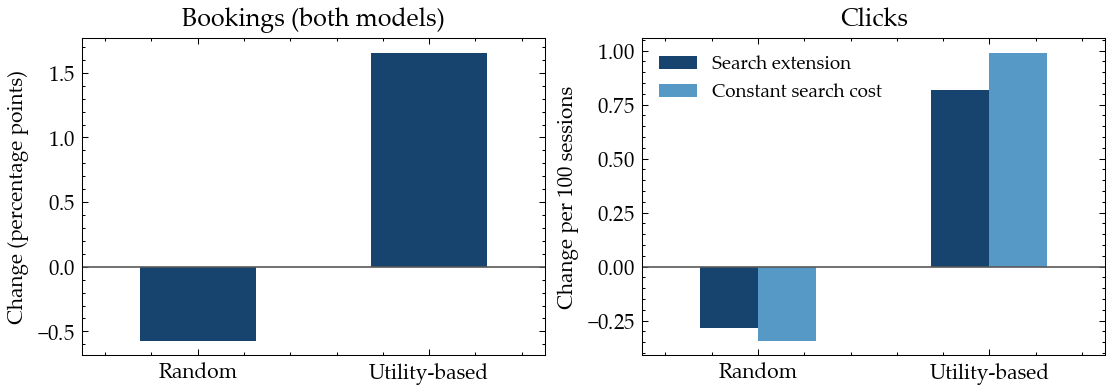

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.6), layout="constrained")
effects = changes.drop(index="Expedia")

effects["Bookings (%)"].plot.bar(ax=axes[0], color=dark_blue, rot=0)
axes[0].set_title("Bookings (both models)")
axes[0].set_ylabel("Change (percentage points)")

(100 * effects[["Extension clicks / session", "Constant-cost clicks / session"]]).rename(columns={
    "Extension clicks / session": "Search extension",
    "Constant-cost clicks / session": "Constant search cost"
}).plot.bar(ax=axes[1], rot=0, color=blues)
axes[1].set_title("Clicks")
axes[1].set_ylabel("Change per 100 sessions")
axes[1].legend(frameon=False, loc="best")

for ax in axes:
    ax.axhline(0, color="0.35", linewidth=0.8)
    ax.set_xlabel("")
fig.savefig(output / "ranking_effects.pdf")
plt.show()

### How to read the ranking results

The extension explains how consumers reach the same booking probabilities through fewer clicks. It holds the booking coefficients fixed. The comparison applies the models to the same recorded choice sets at fixed prices. The data omit sessions with zero clicks and oversample Expedia bookings, so the raw Expedia booking rate has a different interpretation from the predicted level.

**Robustness result.** With constant search costs across positions, the random ranking reduces clicks by 0.34 per 100 sessions versus 0.28 with rank-dependent costs. The utility-based ranking increases clicks by 0.99 versus 0.82. Both specifications give the same direction and a change smaller than one click per 100 sessions. The booking effects are identical because the net booking index is fixed.

### Table of decisions

In [23]:
decisions = pd.DataFrame([
    ["Sample", "Both arms, separate rank slopes", "Random arm only", "Shared coefficients may differ"],
    ["Outside option", "Logit outside option", "External booking rate", "Booking levels shift"],
    ["Selection", "Use recorded sessions", "Model missing nonclickers", "Click levels may shift"],
    ["Taste or search", "Rank in both", "Rank in taste only", "Click effects change"],
    ["Position form", "Linear displayed position", "Log position", "Top moves misvalued"],
    ["Price", "Observed hotel controls", "Valid price instrument", "Markups may be high"],
    ["Policy prices", "Hold prices fixed", "Let prices adjust", "Long-run effect differs"],
    ["Extreme prices", "Clip to USD 10–1,000", "Keep raw prices", "Price slope may shift"]
], columns=["Decision", "Choice", "Alternative", "If choice fails"])
decisions

,Decision,Choice,Alternative,If choice fails
0,Sample,"Both arms, separate rank slopes",Random arm only,Shared coefficients may differ
1,Outside option,Logit outside option,External booking rate,Booking levels shift
2,Selection,Use recorded sessions,Model missing nonclickers,Click levels may shift
3,Taste or search,Rank in both,Rank in taste only,Click effects change
4,Position form,Linear displayed position,Log position,Top moves misvalued
5,Price,Observed hotel controls,Valid price instrument,Markups may be high
6,Policy prices,Hold prices fixed,Let prices adjust,Long-run effect differs
7,Extreme prices,"Clip to USD 10–1,000",Keep raw prices,Price slope may shift


In [24]:
parameters.to_csv(output / "parameters.csv")
fit.to_csv(output / "fit.csv")
economics.to_csv(output / "economics.csv", header=["Value"])
policy.to_csv(output / "policy.csv")
changes.to_csv(output / "policy_changes.csv")

samples.to_csv(output / "samples.csv")
click_curves.to_csv(output / "click_curves.csv", index=False)

### References and AI use

The notation follows Munk-Nielsen (2026), *Demand Estimation*. The model follows Moraga-González, Sándor and Wildenbeest (2023). The hotel attributes and ranking exercise draw on Ursu (2018). [Consumer Search and Prices in the Automobile Market](https://doi.org/10.1093/restud/rdac047). [The Power of Rankings](https://doi.org/10.1287/mksc.2017.1072).

ChatGPT (OpenAI, November 2026) assisted with the derivations, code, numerical checks and report drafting.